# 04 · An independent detector, a chance baseline, and what scales

Notebook 03 checked values against fixed physical limits, which overlap NOAA's own bounds flag, so "nothing slipped past" proved little. This notebook asks three sharper questions on the same 474-station sample (39.4M observations):

1. **Is the batched, resumable build faithful?** It must reproduce the first build exactly.
2. **Does a detector that shares nothing with NOAA's rules agree with NOAA's flags?** It uses each station's own weekly climatology (median and MAD) and no NOAA flag or bound.
3. **Are long runs of identical readings more than rounding and chance would produce?** Compare with the same station's values shuffled within each calendar month.

Unflagged extremes can be genuine weather. They are listed so a person can judge, not counted as errors.

In [1]:
import time, resource
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds
from ghcnd_quality.spark import get_spark
from ghcnd_quality.audit import register_views, register_zscores, run_sql
from ghcnd_quality.runs import load_series, observed_vs_chance, run_lengths

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
spark = get_spark("nb04"); register_views(spark, "../data/parquet"); register_zscores(spark, "../data/derived")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=45241 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=45241 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/10 21:50:14 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/10 21:50:14 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


26/10/10 21:50:15 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1 · The batched build reproduces the first build

In [2]:
a = spark.read.parquet("../data/parquet/daily"); b = spark.read.parquet("../data/parquet_batched/daily")
ca = a.groupBy("element").count().toPandas().set_index("element")["count"].sort_index()
cb = b.groupBy("element").count().toPandas().set_index("element")["count"].sort_index()
print("rows, first build  :", f"{ca.sum():,}")
print("rows, batched build:", f"{cb.sum():,}   (172 batches keyed by station-id prefix)")
print("row counts equal for every element:", ca.equals(cb))
print("rows in one build and not the other:", a.exceptAll(b).count(), "/", b.exceptAll(a).count())
print("duplicate (station, date, element) keys in the batched build:",
      b.groupBy("station_id", "date", "element").count().filter("count > 1").count())

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


rows, first build  : 39,358,220
rows, batched build: 39,358,220   (172 batches keyed by station-id prefix)
row counts equal for every element: True


rows in one build and not the other: 0 / 0


duplicate (station, date, element) keys in the batched build: 0


## 2 · A detector independent of NOAA's flags

For each station, element and 7-day bin of the year, `sql/08_climatology_zscores.sql` computes the median and MAD of that station's own record, and a robust z-score `(value - median) / (1.4826 * MAD)`, with the scale floored at 2 °C. NOAA's flags and bounds are not used. Then `sql/09` cross-tabulates the score against NOAA's flag.

In [3]:
z = run_sql(spark, "09_detector_vs_noaa")
z

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,element,abs_z,observations,flagged_by_noaa,pct_flagged
0,TMAX,0 under 3,9811183,15124,0.154
1,TMAX,1 3 to 4,58915,1223,2.076
2,TMAX,2 4 to 5,12127,678,5.591
3,TMAX,3 5 to 6,3279,587,17.902
4,TMAX,4 6 to 8,1721,1206,70.076
5,TMAX,5 8 or more,1525,1522,99.803
6,TMIN,0 under 3,9716939,20282,0.209
7,TMIN,1 3 to 4,45877,1737,3.786
8,TMIN,2 4 to 5,8222,835,10.156
9,TMIN,3 5 to 6,1893,557,29.424


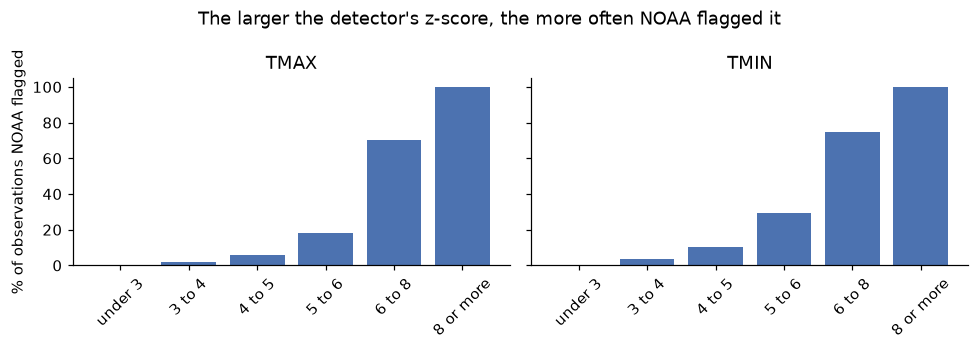

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (el, g) in zip(axs, z.groupby("element")):
    ax.bar(g.abs_z.str[2:], g.pct_flagged, color="#4C72B0"); ax.set_title(el); ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("% of observations NOAA flagged")
fig.suptitle("The larger the detector's z-score, the more often NOAA flagged it"); plt.tight_layout(); plt.show()

In [5]:
big = z[z.abs_z.str.startswith("5")]
print(big[["element", "observations", "flagged_by_noaa"]].to_string(index=False))
print()
print("observations with |z| >= 8 that NOAA did not flag:", int((big.observations - big.flagged_by_noaa).sum()))
mid = z[z.abs_z.isin(["2 4 to 5", "3 5 to 6", "4 6 to 8"])]
print("observations with 4 <= |z| < 8 that NOAA did not flag:", int((mid.observations - mid.flagged_by_noaa).sum()))
low = z[z.abs_z.str.startswith("0")]
print("observations with |z| < 3 that NOAA flagged:", int(low.flagged_by_noaa.sum()), "of", int(low.observations.sum()))

element  observations  flagged_by_noaa
   TMAX          1525             1522
   TMIN          1131             1131

observations with |z| >= 8 that NOAA did not flag: 3
observations with 4 <= |z| < 8 that NOAA did not flag: 23572
observations with |z| < 3 that NOAA flagged: 35406 of 19528122


Reading this: NOAA's flags and a climatology score that uses none of NOAA's rules agree where the evidence is strongest: 99.8% of TMAX and 100% of TMIN observations with |z| >= 8 are NOAA-flagged, rising steadily from 0.2% below |z| 3. They part ways in between: 23,572 observations at 4 <= |z| < 8 are unflagged, and NOAA flags 35,406 observations the detector calls ordinary (|z| < 3), which fits flags that are about duplicates, streaks or inconsistency rather than size. Below are the most extreme observations NOAA did *not* flag, with the seven surrounding days.

In [6]:
run_sql(spark, "10_unflagged_extremes", z_min=8.0, n=12)

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,station_id,name,country_code,element,date,value_c,week_median_c,z,neighbours_pm3d
0,RSM00020667,BELY ISLAND,RS,TMAX,1938-07-01,23.1,2.8,9.1,11.8 9.2 19.1 21.9 8.1 7.2
1,GLW00017605,THULE OP SITE,GL,TMAX,1973-09-23,-21.1,0.0,-8.4,-18.9 -17.8 -20.0 -19.4 -20.0 -20.0
2,BOM00026657,DOKSHITSY,BO,TMAX,1969-12-31,-22.2,1.0,-8.2,-7.2 -2.8 -2.8


Only three observations reach |z| >= 8 without a NOAA flag. Two of them (THULE OP SITE, -21.1 against neighbours of -18 to -20; DOKSHITSY, -22.2 after three missing days and then -7.2) sit among similar neighbours, which looks like real cold weather. BELY ISLAND (23.1 among 7 to 22) swings widely from day to day, so it cannot be judged from these seven days. I would not call any of the three an error, and I cannot call them correct either. The much larger group is the 23,572 unflagged observations at 4 <= |z| < 8, mostly ordinary weather extremes; they are not listed here.

### TAVG outside the day's [TMIN, TMAX]

In [7]:
t = run_sql(spark, "11_tavg_consistency", tol=0.5)
t

/home/claude/venv-spark/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,days_with_all_three,tavg_outside_range,outside_and_nothing_flagged
0,5065662,18667,16612


Of 5,065,662 days that report TAVG, TMIN and TMAX, 18,667 (0.37%) have a TAVG outside [TMIN, TMAX] by more than 0.5 °C, and 16,612 of those have no NOAA flag on any of the three. A daily mean outside its own range is not possible for a true mean of the extremes, but TAVG may be computed from hourly readings, and TMIN/TMAX may cover a different observation window, so this is a pointer to inconsistent definitions or errors, not a count of faulty readings.

In [8]:
spark.stop()   # free the JVM before the pandas sections: this machine has 7 GB

## 3 · Stuck sensors against what chance produces

A run of identical consecutive days is a candidate stuck sensor. But stations that report whole °F in a steady climate repeat values naturally. Compare with the same station and element **shuffled within each calendar month**, which keeps the value distribution (including rounding) and destroys day-to-day persistence. Five shuffles; TMAX and TMIN.

In [9]:
t0 = time.time(); series = load_series("../data/parquet"); print(f"{len(series):,} TMAX/TMIN observations loaded in {time.time()-t0:.0f} s")
chance = observed_vs_chance(series, shuffles=5, seed=0); chance

19,681,114 TMAX/TMIN observations loaded in 11 s


,observed,shuffled (mean),shuffled (max)
10-14 days,238,0.2,1
15-29 days,67,0.0,0
30+ days,21,0.0,0


In [10]:
g, d, v = series["group"].to_numpy(), series["day"].to_numpy(), series["value"].to_numpy()
start, length = run_lengths(g, d, v)
long = start[length >= 10]
flagged = series["qflag"].notna().to_numpy()
# a run is "flagged" if NOAA flagged at least one of its days
cum = np.cumsum(np.append(0, flagged))
n_flag = cum[start[length >= 10] + length[length >= 10]] - cum[long]
runs = pd.DataFrame({"length": length[length >= 10], "flagged_days": n_flag})
runs["bucket"] = pd.cut(runs.length, [9, 14, 29, 10**6], labels=["10-14 days", "15-29 days", "30+ days"])
runs.groupby("bucket", observed=True).agg(runs=("length", "size"), runs_with_a_flagged_day=("flagged_days", lambda s: int((s > 0).sum())))

,runs,runs_with_a_flagged_day
bucket,,
10-14 days,238,11
15-29 days,67,31
30+ days,21,21


The shuffled series produce almost no runs of 10 or more days (mean 0.2 in the shortest bucket, none in the others), while the real series have 238, 67 and 21, so rounding and chance within a month do not explain them. NOAA flagged a day in only 11 of the 238 runs of 10 to 14 days, 31 of 67 of 15 to 29 days, and all 21 of 30 or more. So most short runs are unflagged. They are candidates for a stuck sensor, not confirmed ones: the shuffle keeps each month's values, so a genuinely steady regime in a narrow-range month could still explain a run.

In [11]:
del g, d, v, start, length, long, flagged, cum, runs
import gc; gc.collect()

0

## 4 · What scales, measured

The same aggregate (mean TMAX per station and year) three ways on this sample. Single runs on a 2-core, 7 GB machine, wall-clock; no repeated trials.

In [12]:
spark = get_spark("nb04b")
from ghcnd_quality.dly import read_dly
from pyspark.sql import functions as F
rows = []
def timed(label, fn):
    t0 = time.time(); r = fn(); rows.append({"method": label, "seconds": round(time.time() - t0, 1), "result_rows": r})
timed("Spark: parse raw .dly text, then aggregate",
      lambda: read_dly(spark, "../data/raw/ghcnd_all/*.dly").filter("element = 'TMAX'").groupBy("station_id", "year").agg(F.avg("value")).count())
timed("Spark: read Parquet, aggregate",
      lambda: spark.read.parquet("../data/parquet/daily").filter("element = 'TMAX'").groupBy("station_id", F.year("date")).agg(F.avg("value")).count())
def pandas_agg():
    t = ds.dataset("../data/parquet/daily", format="parquet", partitioning="hive").to_table(
        columns=["station_id", "date", "value"], filter=ds.field("element") == "TMAX").to_pandas()
    return len(t.groupby(["station_id", pd.to_datetime(t["date"]).dt.year])["value"].mean())
timed("pandas: read Parquet, aggregate", pandas_agg)
pd.DataFrame(rows)

26/10/10 21:58:50 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: ../data/raw/ghcnd_all/*.dly.
java.io.FileNotFoundException: File ../data/raw/ghcnd_all/*.dly does not exist
	at org.apache.hadoop.fs.RawLocalFileSystem.deprecatedGetFileStatus(RawLocalFileSystem.java:980)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileLinkStatusInternal(RawLocalFileSystem.java:1301)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileStatus(RawLocalFileSystem.java:970)
	at org.apache.hadoop.fs.FilterFileSystem.getFileStatus(FilterFileSystem.java:462)
	at org.apache.spark.sql.execution.streaming.sinks.FileStreamSink$.hasMetadata(FileStreamSink.scala:58)
	at org.apache.spark.sql.execution.datasources.DataSource.resolveRelation(DataSource.scala:394)
	at org.apache.spark.sql.catalyst.analysis.ResolveDataSource.org$apache$spark$sql$catalyst$analysis$ResolveDataSource$$loadV1BatchSource(ResolveDataSource.scala:210)
	at org.apache.spark.sql.catalyst.

26/10/10 21:58:55 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,method,seconds,result_rows
0,"Spark: parse raw .dly text, then aggregate",35.7,33066
1,"Spark: read Parquet, aggregate",1.9,33066
2,"pandas: read Parquet, aggregate",2.1,33066


In [13]:
peak_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
mem = [l for l in open("/proc/meminfo") if l.startswith("MemTotal")][0].split()[1]
print(f"this notebook process peak memory so far: {peak_gb:.1f} GB (includes the 19.7M-row TMAX/TMIN series held above)")
print(f"machine memory: {int(mem)/1e6:.1f} GB, {__import__('os').cpu_count()} cores")
print(f"TMAX/TMIN series held in pandas: {series.memory_usage(deep=True).sum()/1e9:.2f} GB for {len(series):,} rows "
      f"({series.memory_usage(deep=True).sum()/len(series):.0f} bytes/row)")

this notebook process peak memory so far: 2.2 GB (includes the 19.7M-row TMAX/TMIN series held above)
machine memory: 8.2 GB, 2 cores
TMAX/TMIN series held in pandas: 0.47 GB for 19,681,114 rows (24 bytes/row)


**What this does and does not show.** On this sample, reading Parquet takes about 2 s in Spark and about 2 s in pandas, against 36 s for Spark to parse the raw text first. Spark brings nothing here over pandas; the Parquet layout is what makes repeated audits cheap. The pandas series for TMAX and TMIN holds 19.7M rows at 24 bytes per row (0.47 GB), and the notebook process peaked at 2.2 GB. At that rate roughly 0.3 billion rows would fill this machine's memory before any sort or shuffle copy, and the shuffle baseline needs several copies, so the practical limit is lower (an estimate, not a measurement). The full archive has not been run: the cloud environment cannot reach NOAA, so the batched build is demonstrated on the 474-station sample only.